# Pemodelan 01 — Baseline di Bagian Validasi

Notebook ini menyiapkan tahap pemodelan: memuat tensor hasil preprocessing
dengan pagar data uji, menghitung tujuh model pembanding di bagian validasi, dan
mengukur waktu latih untuk memperkirakan biaya pencarian konfigurasi di
notebook 02. Bagian uji tidak dibuka di notebook ini.

Urutan tiap tahap sama dengan notebook preprocessing: baris `Dasar:` yang
merujuk ke kunci di `references/README.md`, tampilkan data atau masalahnya,
lalu olah dan tampilkan hasilnya.

## Informasi umum

| | |
|---|---|
| Data | Tensor V17 (`processed/tensor_h{1,2,3}.npz`), jendela 14 hari, hujan Daymet tergeser, log1p |
| Bagian yang dipakai | Latih (kode 0) dan validasi (kode 1) saja |
| Target | Debit pos 02035000, dilatih dalam skala z-score, metrik dihitung dalam m³/s |
| Horizon | 1, 2, dan 3 hari, satu model per horizon |
| Model | Klimatologi, persistensi, ARIMA, regresi linear, LSTM target, S_LSTM ala Le, CNN-LSTM |
| Pengaturan jaringan | Pengaturan tengah tahap A (lr 0,001; 64 unit; 2 lapisan LSTM; dropout 0,25; kernel 2; 1 lapisan konvolusi), 3 seed |
| Log | Setiap run jaringan dicatat di `modeling/hasil/log_run.csv` |

## Susunan notebook

| Bagian | Tahap | Isi |
|---|---|---|
| I | 1–2 | Pagar data uji dan metrik |
| II | 3–6 | Pembanding tanpa jaringan saraf: klimatologi, persistensi, ARIMA, regresi linear |
| III | 7–10 | Jaringan saraf pada pengaturan tengah: LSTM target, S_LSTM ala Le, CNN-LSTM |
| IV | 11–12 | Tabel baseline dan perkiraan waktu pencarian di notebook 02 |

Fungsi yang dipakai bersama oleh notebook 01, 02, dan 03 (pemuat data, model,
pelatihan, metrik, dan log) ada di `modeling/pemodelan.py`.

---
## Persiapan

Dasar: deskriptif, tidak ada keputusan metodologis

Sel pertama berisi import, konstanta, dan fungsi bantu. Batas pembagian data
70:15:15 dibaca dari modul `pemodelan`, yang menghitungnya dengan rumus yang
sama dengan tahap 22 preprocessing. Sel kedua adalah sel gaya gambar yang sama
dengan notebook preprocessing.

In [1]:
import json, os, sys, time, warnings
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")
MULAI_JALAN = time.time()

# --- lokasi folder: notebook bisa dijalankan dari root repo maupun dari folder modeling/
ROOT = Path.cwd() if (Path.cwd() / "processed").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "modeling"))
import pemodelan as pm
from pemodelan import muat_latih_val, muat_deret_target, metrik, ke_m3s, jalankan, baca_log

FIGUR, HASIL = pm.FIGUR, pm.HASIL
PERIODE, n_hari = pm.PERIODE, pm.N_HARI
i_latih, i_val = pm.I_LATIH, pm.I_VAL          # batas 70:15:15, lihat tahap 22 preprocessing
TARGET, HORIZON = pm.TARGET, pm.HORIZON
NOTEBOOK = "01_baseline"
SEED_SELEKSI = [0, 1, 2]                        # 3 seed untuk seleksi (brief bagian 1)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

def koma(x, _=None, d=2):
    # Angka dengan koma desimal.
    return f"{x:.{d}f}".replace(".", ",")

def ribu(x):
    # Bilangan bulat dengan titik pemisah ribuan.
    return f"{int(round(x)):,}".replace(",", ".")

def sumbu_koma(ax, sumbu="y", d=1):
    f = FuncFormatter(lambda x, _: koma(x, d=d))
    (ax.yaxis if sumbu == "y" else ax.xaxis).set_major_formatter(f)

import keras, tensorflow as tf
tf.get_logger().setLevel("ERROR")
print(f"TensorFlow {tf.__version__}, Keras {keras.__version__}, perangkat: "
      f"{', '.join(d.device_type for d in tf.config.list_physical_devices())}")
print(f"mesin: {pm.mesin()}")
print(f"batas latih/validasi: {PERIODE[i_latih].date()}, validasi/uji: {PERIODE[i_val].date()}")

TensorFlow 2.20.0, Keras 3.15.1, perangkat: CPU
batas latih/validasi: 2017-07-02, validasi/uji: 2021-04-02


### Gaya gambar

Semua gambar di notebook memakai sel ini. Aturannya:

- **Latar dan teks.** Latar putih, teks judul, label, dan angka sumbu abu-abu gelap
  (`#333333`), gridline tipis abu-abu muda. Ukuran huruf dasar 10 pt.
- **Palet kategorikal.** Enam warna Okabe–Ito versi pudar, yang tetap bisa dibedakan
  oleh pembaca buta warna. Satu gambar memakai paling banyak enam warna. Metode
  pengisian yang sama memakai warna yang sama di semua gambar (`WARNA_METODE`):
  regresi dinamis hijau, MOVE.1 oranye, interpolasi linear abu-abu tua, regresi
  log-log biru langit, DAR ungu, dan isian dari sumber lain pada hari yang sama
  (gridMET, tambal nol dari tetangga) merah bata. Dua versi dari metode yang sama
  dibedakan dengan jenis garis dan penanda. Debit terukur biru, hujan biru langit,
  deret donor abu-abu, nilai berkode `A:e` ungu, dan rentang hari kosong diarsir
  oranye redup.
- **Ketersediaan data.** Dua warna: tersedia biru muda (`#9ecae1`), kosong oranye
  redup (`#d9822b`), dan bulan yang sebagian harinya kosong memakai gradasi di
  antara keduanya.
- **Besaran kontinu** (korelasi, jarak, hujan, luas). Colormap sekuensial satu
  hue (`Blues`), dengan rentang yang disesuaikan dengan data supaya perbedaannya
  terlihat. Angka di dalam sel berwarna gelap atau putih menurut terang latarnya.
- **Batas pembagian data.** Batas latih–validasi dan validasi–uji digambar sebagai
  garis abu-abu putus-putus.
- **Penyimpanan.** Setiap gambar disimpan dengan `simpan_gambar()` ke folder
  `figur/` (PNG, 200 dpi, latar putih), lalu ditampilkan.

In [2]:
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap, Normalize, to_rgb

TEKS = "#333333"        # judul, label, angka sumbu
GRID = "#e3e3e3"        # gridline tipis
BATAS = "#8c8c8c"       # batas latih/validasi/uji

# palet kategorikal: Okabe–Ito versi pudar (6 warna)
PALET = {"biru": "#3d78a8", "oranye": "#d9822b", "hijau": "#3e9c80",
         "merah": "#c4664a", "ungu": "#a87a9f", "langit": "#86b8dc"}
ABU, ABU_TUA, ABU_MUDA = "#9a9a9a", "#5f5f5f", "#cfcfcf"

# peran warna yang dipakai di banyak gambar
WARNA = {
    "utama":  PALET["biru"],     # debit terukur, pos yang dipakai
    "aksen":  PALET["merah"],    # penanda dan garis bantu
    "abu":    ABU,               # pos yang tidak dipakai, deret donor, elemen sekunder
    "hujan":  PALET["langit"],   # hujan
    "risiko": "#f3cfa6",         # isi kotak tahap berisiko kebocoran (oranye pudar)
    "netral": "#e8f0f7",         # isi kotak diagram biasa
    "perkiraan": PALET["ungu"],  # nilai berkode A:e (hasil perkiraan USGS)
    "kosong": "#d9822b",         # hari kosong (sama dengan warna kosong pada peta ketersediaan)
}
# metode pengisian: warna, jenis garis, dan penanda yang sama di semua gambar
WARNA_METODE = {
    "linear": ABU_TUA, "regresi log-log": PALET["langit"], "MOVE.1": PALET["oranye"],
    "DAR φ=0,89": PALET["ungu"], "DAR φ fit": PALET["ungu"],
    "regresi dinamis": PALET["hijau"], "regresi dinamis kausal": PALET["hijau"],
    "sumber lain": PALET["merah"],          # gridMET untuk kabisat Daymet, tambal nol dari tetangga GHCN
}
GARIS_METODE = {"DAR φ fit": "--", "regresi dinamis kausal": "--"}
PENANDA_METODE = {"linear": "o", "regresi log-log": "s", "MOVE.1": "D", "DAR φ=0,89": "v", "DAR φ fit": "^",
                  "regresi dinamis": "P", "regresi dinamis kausal": "X", "sumber lain": "s"}

def potong_cmap(nama, a=0.0, b=1.0):
    """Bagian a..b dari colormap, misalnya supaya garis berwarna terang tetap terlihat di latar putih."""
    return LinearSegmentedColormap.from_list(f"{nama}_{a}_{b}", plt.get_cmap(nama)(np.linspace(a, b, 256)))

CMAP_TERSEDIA = LinearSegmentedColormap.from_list("tersedia", ["#d9822b", "#9ecae1"])   # kosong -> tersedia
CMAP_SEKUENSIAL = plt.get_cmap("Blues")                 # korelasi, hujan, jarak (dibalik)
CMAP_GARIS = potong_cmap("Blues", 0.35, 0.95)           # garis yang diwarnai menurut besaran kontinu

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "text.color": TEKS, "axes.labelcolor": TEKS, "axes.titlecolor": TEKS,
    "xtick.color": TEKS, "ytick.color": TEKS, "axes.edgecolor": "#8c8c8c", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "image.cmap": "Blues",
    "axes.prop_cycle": cycler(color=list(PALET.values())),
})

def simpan_gambar(fig, nama):
    """Simpan gambar ke figur/<nama>.png (200 dpi, latar putih), lalu tampilkan."""
    fig.savefig(FIGUR / f"{nama}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

def warna_teks(latar):
    """Warna angka di atas sel: abu-abu gelap di latar terang, putih di latar gelap."""
    r, g, b = to_rgb(latar)
    return TEKS if 0.299 * r + 0.587 * g + 0.114 * b > 0.55 else "white"

def heatmap(ax, M, cmap, vmin, vmax, fmt=None, ukuran=9, tebal=None, lewati=None, aspect="equal", extent=None):
    """imshow tanpa grid dan bingkai; bila fmt diberikan, nilai ditulis di tiap sel dengan warna otomatis.
    tebal: sel yang angkanya ditebalkan; lewati: sel yang angkanya tidak ditulis (boolean, bentuk sama dengan M)."""
    A = np.asarray(M, float)
    cm_, nrm = plt.get_cmap(cmap), Normalize(vmin, vmax)
    im = ax.imshow(A, cmap=cm_, norm=nrm, aspect=aspect, interpolation="nearest", extent=extent)
    ax.grid(False)
    for s_ in ax.spines.values():
        s_.set_visible(False)
    if fmt is not None:
        for i in range(A.shape[0]):
            for j in range(A.shape[1]):
                if np.isfinite(A[i, j]) and not (lewati is not None and lewati[i, j]):
                    ax.text(j, i, fmt(A[i, j]), ha="center", va="center", fontsize=ukuran,
                            color=warna_teks(cm_(nrm(A[i, j]))),
                            fontweight="bold" if tebal is not None and tebal[i, j] else "normal")
    return im

def batas_bagian(ax, ke_x=lambda t: t, label=True, y_label=1.01):
    """Garis putus-putus abu-abu di batas latih-validasi dan validasi-uji; label bagian di atas sumbu."""
    x_l, x_v = ke_x(PERIODE[i_latih]), ke_x(PERIODE[i_val])
    for x_ in (x_l, x_v):
        ax.axvline(x_, color=BATAS, lw=1.0, ls="--", zorder=1)
    if label:
        tr = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
        for t_, teks in [(PERIODE[i_latih // 2], "latih"), (PERIODE[(i_latih + i_val) // 2], "validasi"),
                         (PERIODE[(i_val + n_hari) // 2], "uji")]:
            ax.text(ke_x(t_), y_label, teks, transform=tr, ha="center", va="bottom", fontsize=9, color=ABU_TUA)

def bagian_dari(t):
    """Nama bagian data (latih/validasi/uji) untuk satu tanggal."""
    i_ = PERIODE.get_loc(pd.Timestamp(t))
    return ["latih", "validasi", "uji"][int(i_ >= i_latih) + int(i_ >= i_val)]

def rentang_gap(s):
    """Daftar (mulai, akhir, panjang) setiap rentetan NaN pada deret s."""
    k = s.isna().to_numpy()
    d_ = np.diff(np.r_[0, k.astype(int), 0])
    return [(s.index[a], s.index[b - 1], b - a) for a, b in zip(np.where(d_ == 1)[0], np.where(d_ == -1)[0])]

print("gaya gambar: palet", ", ".join(PALET), "| colormap sekuensial Blues | gambar disimpan ke", FIGUR.relative_to(ROOT))

gaya gambar: palet biru, oranye, hijau, merah, ungu, langit | colormap sekuensial Blues | gambar disimpan ke figur


---
# Bagian I — Pagar data uji dan metrik

## 1. Pagar data uji

Dasar: [Roberts2017] dan [Le2025] untuk pembagian menurut waktu; pemilihan
konfigurasi hanya di bagian validasi dan bagian uji disentuh sekali di akhir:
arahan penelitian; pagar dan assert: pilihan sendiri

Semua pilihan di notebook 01 dan 02 diambil dari bagian validasi. Supaya bagian
uji tidak ikut terbaca secara tidak sengaja, data hanya dimuat lewat dua fungsi
di `pemodelan.py`:

- `muat_latih_val(h)` membuka tensor horizon h, membuang semua sampel berkode
  bagian 2 dan 3 sebelum mengembalikan apa pun, lalu memanggil `pagar_uji`.
- `muat_deret_target()` membaca debit pos target hanya sampai hari terakhir
  bagian validasi (dipakai ARIMA dan klimatologi).

`pagar_uji` gagal bila ada kode bagian selain 0 dan 1, atau bila ada indeks
target di atas hari terakhir bagian validasi. Bagian uji hanya bisa dibuka
lewat `muat_uji`, yang menolak berjalan sebelum notebook 02 menulis dan mengunci
`modeling/konfigurasi_final.json`.

Sel berikut menampilkan isi file tensor. Yang dibaca hanya larik kode bagian
dan indeks target; tensor X dan target y tidak dibaca.

In [3]:
baris = []
for h in HORIZON:
    with np.load(pm.PROC / f"tensor_h{h}.npz") as f:
        bag, idx = f["bagian"], f["idx"]
    baris.append({"horizon": h, **{f"kode_{k}": int((bag == k).sum()) for k in range(4)},
                  "hari_target_pertama_uji": str(PERIODE[idx[bag >= 2].min()].date())})
pd.DataFrame(baris).set_index("horizon")

,kode_0,kode_1,kode_2,kode_3,hari_target_pertama_uji
horizon,,,,,
1,6378,1370,1322,48,2021-04-02
2,6377,1370,1322,48,2021-04-02
3,6376,1370,1322,48,2021-04-02


In [4]:
DATA = {h: muat_latih_val(h) for h in HORIZON}
ringkas = pd.DataFrame([{
    "horizon": h,
    "latih": len(D["y_latih"]), "validasi": len(D["y_val"]),
    "target_latih": f"{PERIODE[D['idx_latih'].min()].date()} s.d. {PERIODE[D['idx_latih'].max()].date()}",
    "target_validasi": f"{PERIODE[D['idx_val'].min()].date()} s.d. {PERIODE[D['idx_val'].max()].date()}",
    "validasi_target_A:e": int((~D["murni_val"]).sum()),
    "bentuk_X": str(D["X_latih"].shape[1:]),
} for h, D in DATA.items()]).set_index("horizon")
print(ringkas.to_string())

q_target = muat_deret_target()
print(f"\nderet target untuk ARIMA dan klimatologi: {q_target.index[0].date()} s.d. {q_target.index[-1].date()} "
      f"({ribu(len(q_target))} hari)")
assert np.allclose(ke_m3s(DATA[1]["y_val"], DATA[1]), q_target.to_numpy()[DATA[1]["idx_val"]], rtol=1e-4, atol=1e-2)
print("target tensor (dikembalikan ke m³/s) sama dengan deret debit pos target")

# pagar harus gagal bila diberi sampel uji
uji_pagar = [("kode bagian 2", np.array([10, 7000]), np.array([0, 2])),
             ("kode bagian 3", np.array([10, 7000]), np.array([0, 3])),
             ("indeks target di bagian uji", np.array([10, i_val]), np.array([0, 1]))]
print()
for nama, idx_, bag_ in uji_pagar:
    try:
        pm.pagar_uji(idx_, bag_)
        raise RuntimeError(f"pagar tidak bekerja untuk {nama}")
    except AssertionError as e:
        print(f"{nama:28}: gagal seperti seharusnya ({e})")
try:
    pm.muat_uji(1)
    raise RuntimeError("muat_uji terbuka sebelum konfigurasi dikunci")
except AssertionError as e:
    print(f"{'muat_uji sebelum dikunci':28}: gagal seperti seharusnya ({e})")

         latih  validasi                target_latih             target_validasi  validasi_target_A:e      bentuk_X
horizon                                                                                                            
1         6378      1370  2000-01-15 s.d. 2017-07-01  2017-07-02 s.d. 2021-04-01                   59  (14, 17, 10)
2         6377      1370  2000-01-16 s.d. 2017-07-01  2017-07-02 s.d. 2021-04-01                   59  (14, 17, 10)
3         6376      1370  2000-01-17 s.d. 2017-07-01  2017-07-02 s.d. 2021-04-01                   59  (14, 17, 10)

deret target untuk ARIMA dan klimatologi: 2000-01-01 s.d. 2021-04-01 (7.762 hari)
target tensor (dikembalikan ke m³/s) sama dengan deret debit pos target

kode bagian 2               : gagal seperti seharusnya (PAGAR: sampel uji (kode bagian 2/3) ikut termuat)
kode bagian 3               : gagal seperti seharusnya (PAGAR: sampel uji (kode bagian 2/3) ikut termuat)
indeks target di bagian uji : gagal seperti seharusn

### Hasil

- Pemuat mengembalikan 6.378, 6.377, dan 6.376 sampel latih serta 1.370 sampel
  validasi untuk horizon 1, 2, dan 3. Ke-1.370 sampel uji (1.322 berkode 2 dan
  48 berkode 3) tidak ikut termuat; target validasi terakhir jatuh pada
  1 April 2021, sehari sebelum bagian uji.
- Target tensor yang dikembalikan ke m³/s sama dengan deret debit pos target.
- Keempat pemeriksaan pagar gagal seperti seharusnya: kode bagian 2, kode
  bagian 3, indeks target di bagian uji, dan `muat_uji` sebelum konfigurasi
  dikunci.
- Ada 59 sampel validasi yang targetnya `A:e`. Sampel ini tetap dipakai, karena
  aturan kode 3 hanya berlaku di bagian uji.

## 2. Metrik evaluasi

Dasar: [Le2025] untuk RMSE, MAE, dan NSE (SMAPE ditambahkan di notebook 03);
[Gupta2009] untuk KGE; [Krause2005] untuk dominasi debit tinggi pada NSE

Prediksi jaringan dikembalikan dari z-score ke m³/s sebelum metrik dihitung.
Kriteria seleksi di notebook 02 adalah rata-rata NSE validasi pada horizon 1–3,
dirata-rata atas seed. Karena NSE didominasi debit tinggi (tahap 21
preprocessing), KGE, RMSE, dan MAE ikut dilaporkan.

Aturan `A:e` (kode 3) hanya berlaku di bagian uji, jadi metrik validasi memakai
semua sampel validasi. Jumlah sampel validasi yang targetnya `A:e` ditampilkan di
tahap 1.

Gambar berikut menampilkan target yang harus diprediksi di bagian validasi,
beserta ambang kuartil 1 dan 3 dari data latih.

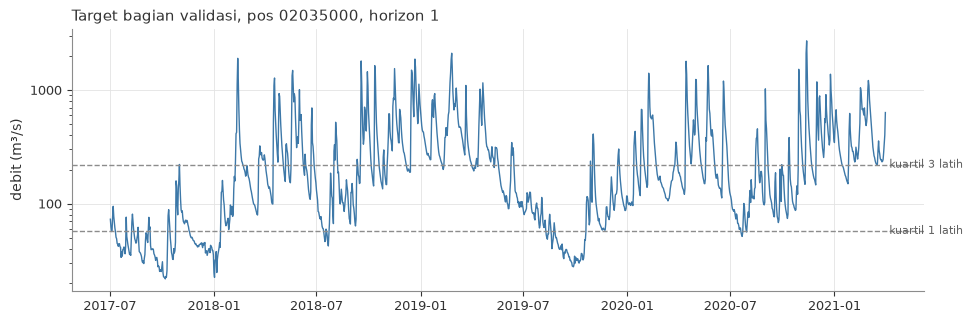

sampel validasi: 1.370; di bawah kuartil 1: 16,6%; di atas kuartil 3: 38,8%; maksimum 2.710 m³/s


In [5]:
WARNA_MODEL = {"klimatologi": ABU, "persistensi": ABU_TUA, "ARIMA": PALET["ungu"],
               "regresi linear": PALET["oranye"], "LSTM target": PALET["langit"],
               "S_LSTM ala Le": PALET["hijau"], "CNN-LSTM": PALET["biru"]}
q1, q3 = pm.META["ambang_aliran"]["rendah_kuartil1"], pm.META["ambang_aliran"]["tinggi_kuartil3"]
D1 = DATA[1]
obs_val = ke_m3s(D1["y_val"], D1)

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(D1["tanggal_val"], obs_val, color=WARNA["utama"], lw=1, label="debit terukur")
for nilai, teks in [(q1, "kuartil 1 latih"), (q3, "kuartil 3 latih")]:
    ax.axhline(nilai, color=BATAS, lw=1, ls="--")
    ax.text(D1["tanggal_val"][-1], nilai, f" {teks}", va="center", fontsize=8, color=ABU_TUA)
ax.set_yscale("log"); ax.set_ylabel("debit (m³/s)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda y_, _: f"{y_:g}".replace(".", ",")))
ax.set_title(f"Target bagian validasi, pos {TARGET}, horizon 1", loc="left")
simpan_gambar(fig, "validasi_target")
print(f"sampel validasi: {ribu(len(obs_val))}; di bawah kuartil 1: {koma((obs_val < q1).mean()*100, d=1)}%; "
      f"di atas kuartil 3: {koma((obs_val > q3).mean()*100, d=1)}%; maksimum {ribu(obs_val.max())} m³/s")

---
# Bagian II — Pembanding tanpa jaringan saraf

Keempat pembanding di bagian ini tidak dilatih dengan gradien dan tidak punya
seed. Hasilnya disimpan di `HASIL_VAL`, dengan kunci (model, horizon).

## 3. Klimatologi

Dasar: lantai terbawah; tidak ada di literatur — pilihan sendiri

Prediksi untuk hari target adalah rata-rata debit pos target pada tanggal
kalender yang sama (bulan dan hari) di bagian latih. Model ini tidak memakai
data hari t sama sekali, jadi prediksinya sama untuk ketiga horizon. Sebelum
dihitung, gambar berikut menampilkan debit bagian latih per tahun kalender.

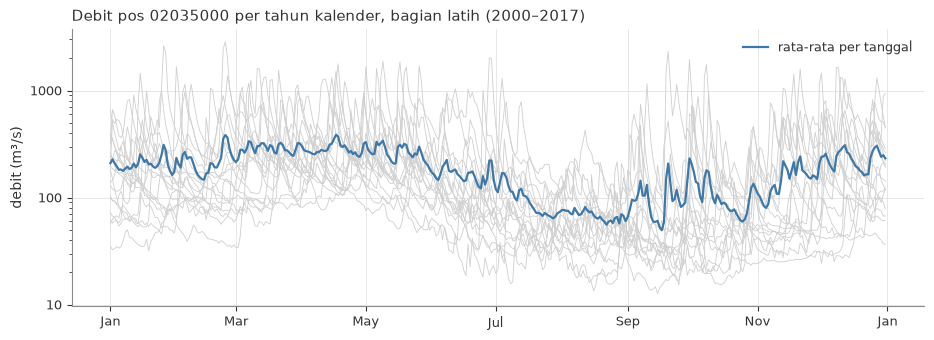

tanggal kalender: 366; tahun per tanggal: 5–18


In [6]:
q_latih = q_target.iloc[:i_latih]
kunci_hari = lambda t: t.strftime("%m-%d")
klim = q_latih.groupby(kunci_hari(q_latih.index)).mean()

fig, ax = plt.subplots(figsize=(11, 3.6))
for th, s in q_latih.groupby(q_latih.index.year):
    x_ = pd.to_datetime("2001-" + kunci_hari(s.index[s.index.strftime("%m-%d") != "02-29"]))
    ax.plot(x_, s[s.index.strftime("%m-%d") != "02-29"].to_numpy(), color=ABU_MUDA, lw=0.6)
x_k = pd.to_datetime("2001-" + klim.index[klim.index != "02-29"])
ax.plot(x_k, klim[klim.index != "02-29"].to_numpy(), color=WARNA["utama"], lw=1.6, label="rata-rata per tanggal")
ax.set_yscale("log"); ax.set_ylabel("debit (m³/s)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda y_, _: f"{y_:g}".replace(".", ",")))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_title(f"Debit pos {TARGET} per tahun kalender, bagian latih ({q_latih.index[0].year}–{q_latih.index[-1].year})", loc="left")
ax.legend(loc="upper right")
simpan_gambar(fig, "klimatologi_latih")
print(f"tanggal kalender: {len(klim)}; tahun per tanggal: {q_latih.groupby(kunci_hari(q_latih.index)).size().min()}"
      f"–{q_latih.groupby(kunci_hari(q_latih.index)).size().max()}")

In [7]:
HASIL_VAL = {}
for h, D in DATA.items():
    pred = klim.reindex(kunci_hari(D["tanggal_val"])).to_numpy()
    assert np.isfinite(pred).all()
    HASIL_VAL[("klimatologi", h)] = metrik(ke_m3s(D["y_val"], D), pred)
pd.DataFrame({h: HASIL_VAL[("klimatologi", h)] for h in HORIZON}).round(3)

,1,2,3
NSE,0.018,0.018,0.018
KGE,-0.046,-0.046,-0.046
RMSE,301.757,301.757,301.757
MAE,166.796,166.796,166.796


### Hasil

NSE klimatologi di validasi hanya 0,018 dan KGE-nya −0,046, hampir sama dengan
memprediksi rata-rata. Rata-rata per tanggal dari 17–18 tahun (5 tahun untuk
29 Februari) tidak menangkap kejadian hujan, yang mendominasi variasi debit
harian. Ini lantai terbawah, dan semua model lain harus jauh di atasnya.

## 4. Persistensi

Dasar: lantai naif; tidak ada di literatur — pilihan sendiri

Prediksi untuk hari t + h adalah debit pos target hari t, yaitu nilai terakhir
di jendela masukan (channel 0, pos target). Sebelum dihitung, sel berikut
menampilkan autokorelasi debit pos target di bagian latih pada lag 1–3, yang
menentukan seberapa sulit lantai ini dikalahkan.

In [8]:
for lag in HORIZON:
    print(f"autokorelasi debit latih, lag {lag}: {koma(q_latih.autocorr(lag), d=3)}")
for h, D in DATA.items():
    pred = ke_m3s(D["X_val"][:, -1, D["i_target"], 0], D)
    assert np.allclose(pred, q_target.to_numpy()[D["idx_val"] - h], rtol=1e-4, atol=1e-2)
    HASIL_VAL[("persistensi", h)] = metrik(ke_m3s(D["y_val"], D), pred)
pd.DataFrame({h: HASIL_VAL[("persistensi", h)] for h in HORIZON}).round(3)

autokorelasi debit latih, lag 1: 0,853
autokorelasi debit latih, lag 2: 0,644
autokorelasi debit latih, lag 3: 0,524


,1,2,3
NSE,0.686,0.272,0.020
KGE,0.843,0.636,0.510
RMSE,170.761,259.841,301.523
MAE,68.379,115.122,143.188


### Hasil

Autokorelasi debit latih turun cepat: 0,853 pada lag 1, 0,644 pada lag 2, dan
0,524 pada lag 3. Akibatnya NSE persistensi 0,686 pada horizon 1, tetapi hanya
0,272 pada horizon 2 dan 0,020 pada horizon 3, setara dengan klimatologi.
Persistensi adalah lantai yang sulit untuk horizon 1 saja.

## 5. ARIMA

Dasar: pembanding statistik dengan riwayat target saja; transformasi log, uji
ADF, dan pemilihan orde dengan AIC pada bagian latih — pilihan sendiri

Hasil ARIMA dari tahap sebelumnya tidak tersimpan di repo, jadi ARIMA dihitung
ulang pada deret target V17. Langkahnya:

1. Debit dilogaritmakan, karena sebarannya menceng dan galat ARIMA dianggap
   Gaussian.
2. Uji ADF pada bagian latih menentukan orde diferensiasi d.
3. Orde p dan q (0–3) dipilih dengan AIC pada bagian latih saja.
4. Parameter dikunci, lalu filter Kalman dijalankan sampai akhir bagian
   validasi. Prakiraan h langkah dari setiap hari asal dihitung dari state
   ramalan filter, sehingga setiap prakiraan hanya memakai data sampai hari asal.
5. Prakiraan dikembalikan dengan eksponen (median sebaran log-normal).

Tampilkan dulu: hasil uji ADF dan tabel AIC.

In [9]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller

lq = np.log(q_target)
lq_latih = lq.iloc[:i_latih].to_numpy()
adf = adfuller(lq_latih, autolag="AIC")
d_arima = 0 if adf[1] < 0.05 else 1
print(f"ADF log-debit latih: statistik {adf[0]:.2f}, p = {adf[1]:.4f}, lag {adf[2]} -> d = {d_arima}")

TREN = "c" if d_arima == 0 else "n"
def fit_arima(y, orde):
    # L-BFGS sampai 1.000 iterasi; batas bawaan statsmodels (50) membuat orde tinggi berhenti sebelum konvergen
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return SARIMAX(y, order=orde, trend=TREN).fit(disp=False, maxiter=1000)

t0 = time.perf_counter()
aic, konvergen = {}, {}
for p in range(4):
    for q in range(4):
        if p == q == 0:
            continue
        r_ = fit_arima(lq_latih, (p, d_arima, q))
        aic[(p, q)], konvergen[(p, q)] = r_.aic, bool(r_.mle_retvals["converged"])
tabel_aic = pd.Series(aic).unstack().rename_axis(index="p", columns="q")
sah = {k: v for k, v in aic.items() if konvergen[k]}
p_arima, q_arima = min(sah, key=sah.get)
urut = sorted(sah.values())
print(f"model konvergen: {len(sah)} dari {len(aic)}")
print(f"orde terpilih: ARIMA({p_arima},{d_arima},{q_arima}), AIC {koma(urut[0], d=1)}; "
      f"selisih dengan orde kedua {koma(urut[1] - urut[0], d=1)}; waktu {time.perf_counter() - t0:.0f} detik\n")
tabel_aic.round(1)

ADF log-debit latih: statistik -6.53, p = 0.0000, lag 25 -> d = 0


model konvergen: 15 dari 15
orde terpilih: ARIMA(3,0,2), AIC -114,1; selisih dengan orde kedua 0,1; waktu 19 detik



q,0,1,2,3
p,,,,
0,NaN,9885.1,5625.6,3554.0
1,869.3,19.3,19.7,-8.4
2,202.0,20.1,-102.4,-114.0
3,-10.7,-30.2,-114.1,-107.2


In [10]:
ORDE = (p_arima, d_arima, q_arima)
res_latih = fit_arima(lq_latih, ORDE)
assert res_latih.mle_retvals["converged"]
res_semua = SARIMAX(lq.to_numpy(), order=ORDE, trend=TREN).filter(res_latih.params)   # parameter dikunci
print(res_latih.summary().tables[1])

ssm = res_semua.model.ssm
def matriks(nama, dim):
    # Matriks sistem pada waktu pertama; matriks yang berubah menurut waktu punya satu sumbu tambahan.
    M = np.asarray(ssm[nama])
    return M[..., 0] if M.ndim > dim else M
T_, c_ = matriks("transition", 2), matriks("state_intercept", 1)
Z_, d_ = matriks("design", 2), matriks("obs_intercept", 1)
a_ramal = res_semua.predicted_state          # kolom t: state hari t dari data sampai hari t-1

def prakiraan_arima(asal, h):
    # Prakiraan log-debit hari asal + h dari data sampai hari asal.
    a = a_ramal[:, asal + 1]
    for _ in range(h - 1):
        a = c_[:, None] + T_ @ a
    return (d_[:, None] + Z_ @ a).ravel()

# cek: horizon 1 sama dengan prediksi satu langkah statsmodels; horizon 3 sama dengan forecast dari data terpotong
asal_cek = int(DATA[3]["idx_val"][100] - 3)
r_cek = SARIMAX(lq.to_numpy()[:asal_cek + 1], order=ORDE, trend=TREN).filter(res_latih.params)
assert np.allclose(prakiraan_arima(np.array([asal_cek]), 3), r_cek.forecast(3)[-1])
assert np.allclose(prakiraan_arima(np.arange(i_latih, i_val - 1), 1), res_semua.predict()[i_latih + 1:i_val])
print("\nprakiraan h langkah sama dengan forecast statsmodels pada data yang dipotong di hari asal")

PRED_ARIMA = {}
for h, D in DATA.items():
    PRED_ARIMA[h] = np.exp(prakiraan_arima(D["idx_val"] - h, h))
    HASIL_VAL[("ARIMA", h)] = metrik(ke_m3s(D["y_val"], D), PRED_ARIMA[h])
pd.DataFrame({h: HASIL_VAL[("ARIMA", h)] for h in HORIZON}).round(3)

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0122      0.004      3.435      0.001       0.005       0.019
ar.L1          1.8910      0.029     65.650      0.000       1.835       1.947
ar.L2         -1.0065      0.054    -18.531      0.000      -1.113      -0.900
ar.L3          0.1130      0.028      3.970      0.000       0.057       0.169
ma.L1         -0.5881      0.028    -20.698      0.000      -0.644      -0.532
ma.L2         -0.3025      0.028    -10.888      0.000      -0.357      -0.248
sigma2         0.0574      0.000    129.517      0.000       0.056       0.058

prakiraan h langkah sama dengan forecast statsmodels pada data yang dipotong di hari asal


,1,2,3
NSE,0.705,0.413,0.279
KGE,0.850,0.590,0.410
RMSE,165.545,233.421,258.627
MAE,57.074,94.071,114.175


### Hasil

- Uji ADF menolak akar unit pada log-debit latih (p < 0,0001), jadi d = 0.
- Dengan batas iterasi bawaan statsmodels (50), orde tinggi berhenti sebelum
  konvergen; dengan 1.000 iterasi, ke-15 model konvergen. AIC terkecil adalah
  ARIMA(3,0,2) (−114,1), hanya 0,1 di bawah ARIMA(2,0,3), jadi kedua orde
  praktis setara.
- NSE validasi 0,705, 0,413, dan 0,279. ARIMA hanya sedikit di atas
  persistensi pada horizon 1, tetapi jauh di atasnya pada horizon 2 dan 3.
- Pada kenaikan debit, ARIMA cenderung melampaui puncak sehari setelahnya
  (gambar di tahap 11), karena model hanya melihat riwayat target dan
  memperpanjang kenaikan yang sudah terjadi.

## 6. Regresi linear

Dasar: pembanding untuk sinyal spasial yang linear; tidak ada di literatur —
pilihan sendiri

Masukan adalah semua kanal dari 17 pos pada hari t (170 fitur), tanpa riwayat
waktu. Koefisien dihitung dengan kuadrat terkecil biasa pada bagian latih.
Atribut statis bernilai tetap di semua sampel, sehingga kolomnya kolinear dengan
intersep; `lstsq` mengambil solusi norma minimum, dan prediksinya tidak
terpengaruh.

Tampilkan dulu: korelasi debit hari t setiap pos dengan target hari t + 1 di
bagian latih.

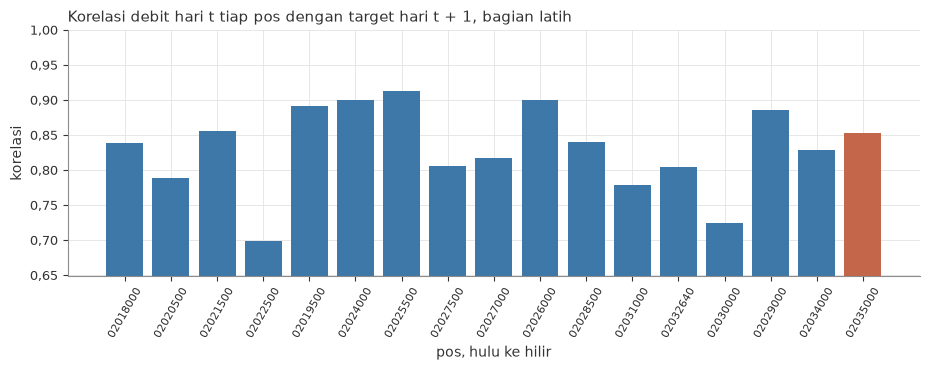

fitur: 170 + intersep; rank matriks latih 70


,1,2,3
NSE,0.899,0.584,0.341
KGE,0.944,0.697,0.447
RMSE,96.679,196.511,247.326
MAE,35.679,81.111,114.955


In [11]:
D1 = DATA[1]
kor = [np.corrcoef(D1["X_latih"][:, -1, j, 0], D1["y_latih"])[0, 1] for j in range(len(D1["pos"]))]
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(range(len(kor)), kor, color=[WARNA["aksen"] if p == TARGET else WARNA["utama"] for p in D1["pos"]])
ax.set_xticks(range(len(kor))); ax.set_xticklabels(D1["pos"], rotation=60, fontsize=8)
ax.set_ylim(min(kor) - 0.05, 1); sumbu_koma(ax, d=2)
ax.set_ylabel("korelasi"); ax.set_xlabel("pos, hulu ke hilir")
ax.set_title("Korelasi debit hari t tiap pos dengan target hari t + 1, bagian latih", loc="left")
simpan_gambar(fig, "korelasi_pos_target_h1")

for h, D in DATA.items():
    F_l = D["X_latih"][:, -1].reshape(len(D["X_latih"]), -1)
    F_v = D["X_val"][:, -1].reshape(len(D["X_val"]), -1)
    A_l = np.c_[np.ones(len(F_l)), F_l]
    koef, *_ = np.linalg.lstsq(A_l, D["y_latih"].astype(float), rcond=None)
    pred = ke_m3s(np.c_[np.ones(len(F_v)), F_v] @ koef, D)
    HASIL_VAL[("regresi linear", h)] = metrik(ke_m3s(D["y_val"], D), pred)
print(f"fitur: {F_l.shape[1]} + intersep; rank matriks latih {np.linalg.matrix_rank(A_l)}")
pd.DataFrame({h: HASIL_VAL[("regresi linear", h)] for h in HORIZON}).round(3)

### Hasil

- Debit hari t di semua pos berkorelasi kuat dengan debit pos target hari
  t + 1 (0,70–0,91); korelasi pos target sendiri 0,85.
- Regresi linear dengan 170 fitur hari t mencapai NSE 0,899, 0,584, dan 0,341.
  Pada ketiga horizon hasilnya di atas ARIMA, dan juga di atas LSTM target
  (tahap 8). Jadi informasi pos hulu pada hari t saja, digabung secara linear,
  sudah lebih berguna daripada riwayat 14 hari pos target.
- Rank matriks latih hanya 70 dari 171 kolom, karena atribut statis tetap di
  semua sampel dan flag isian hampir selalu nol.

---
# Bagian III — Jaringan saraf pada pengaturan tengah

## 7. Pengaturan pelatihan bersama

Dasar: [Kingma2014] dan [Le2025] untuk Adam; [Klotz2022] dan [Weißenborn2025]
untuk batch 256; [Le2025] dan [Prechelt1998] untuk early stopping; [Le2025] dan
[He2015] untuk he_normal; [Ghimire2021] untuk epoch maksimum 300;
[Kratzert2018] untuk loss MSE; [Kratzert2019] untuk seed berulang

Ketiga jaringan dilatih dengan pengaturan yang sama. Pengaturan tetap berlaku di
semua tahap. Pengaturan tengah adalah titik awal tahap A di notebook 02, bukan
konfigurasi terbaik; di notebook ini pengaturan tengah dipakai supaya ketiga
jaringan dibandingkan pada titik yang sama sebelum dituning.

| Pengaturan | Nilai | Dasar |
|---|---|---|
| Optimizer | Adam | [Kingma2014]; [Le2025]; [Ghimire2021] |
| Batch | 256 | [Klotz2022]; [Weißenborn2025] |
| Loss | MSE pada target z-score | [Kratzert2018]; [Klotz2022] |
| Early stopping | val_loss, patience 50, min_delta 1e-5, bobot epoch terbaik | [Le2025]; [Prechelt1998] |
| Epoch maksimum | 300 | [Ghimire2021] |
| Inisialisasi | he_normal untuk kernel konvolusi, LSTM, dan Dense | [Le2025]; [He2015] |
| Learning rate (tengah) | 0,001 | [Ghimire2021]; [Klotz2022]; [Kingma2014] |
| Unit LSTM dan filter (tengah) | 64 | [Le2025] |
| Lapisan LSTM (tengah) | 2 | [Le2025]; [Kratzert2018] |
| Dropout (tengah) | 0,25, setelah blok konvolusi dan setelah setiap lapisan LSTM | [Le2025] |
| Kernel dan lapisan konvolusi (tengah) | 2 dan 1 | [Le2025] |
| Seed | 0, 1, 2 | 3 seed: pilihan sendiri karena biaya; 8 seed untuk final [Kratzert2019] |

Validasi dipakai untuk early stopping, sama dengan Le2025. Bagian validasi yang
sama juga dipakai untuk memilih konfigurasi di notebook 02, sehingga NSE
validasi sedikit optimistis; perbandingan yang tidak bias baru diperoleh di
bagian uji (notebook 03).

Pelatihan memakai TensorFlow 2.20 dan Keras 3. Perangkat keras dicatat di kolom
`mesin` pada log, dan run hanya dipakai ulang pada perangkat yang sama, karena
hasil numerik CPU dan GPU sedikit berbeda. Seed Python, NumPy, dan
TensorFlow diatur lewat `keras.utils.set_random_seed`, dan operasi deterministik
diaktifkan, sehingga run dengan seed yang sama menghasilkan bobot yang sama.
Bila sebuah run dengan konfigurasi dan seed yang sama sudah ada di log,
hasilnya dimuat dari log dan tidak dilatih ulang.

Tampilkan dulu: struktur ketiga jaringan pada pengaturan tengah.

In [12]:
print("pengaturan tetap :", pm.TETAP)
print("pengaturan tengah:", pm.TENGAH)
NAMA_MODEL = {"lstm_target": "LSTM target", "s_lstm": "S_LSTM ala Le", "cnn_lstm": "CNN-LSTM"}
D1 = DATA[1]
for kode_m, nama in NAMA_MODEL.items():
    Xb = pm.bentuk_masukan(D1["X_latih"][:2], kode_m, D1["i_target"])
    m_ = pm.bangun_model(kode_m, pm.TENGAH, Xb.shape[1:])
    print(f"\n{nama}: masukan {Xb.shape[1:]}, {ribu(m_.count_params())} parameter")
    for lap in m_.layers[1:]:
        print(f"  {lap.__class__.__name__:8} -> {tuple(lap.output.shape[1:])}")

pengaturan tetap : {'optimizer': 'adam', 'batch': 256, 'loss': 'mse', 'epoch_maks': 300, 'patience': 50, 'min_delta': 1e-05, 'inisialisasi': 'he_normal'}
pengaturan tengah: {'lr': 0.001, 'unit': 64, 'lapisan_lstm': 2, 'dropout': 0.25, 'kernel': 2, 'lapisan_konv': 1}

LSTM target: masukan (14, 10), 52.289 parameter
  LSTM     -> (14, 64)
  Dropout  -> (14, 64)
  LSTM     -> (64,)
  Dropout  -> (64,)
  Dense    -> (1,)

S_LSTM ala Le: masukan (14, 170), 93.249 parameter
  LSTM     -> (14, 64)
  Dropout  -> (14, 64)
  LSTM     -> (64,)
  Dropout  -> (64,)
  Dense    -> (1,)

CNN-LSTM: masukan (14, 17, 10), 313.217 parameter
  Conv2D   -> (14, 16, 64)
  Dropout  -> (14, 16, 64)
  Reshape  -> (14, 1024)
  LSTM     -> (14, 64)
  Dropout  -> (14, 64)
  LSTM     -> (64,)
  Dropout  -> (64,)
  Dense    -> (1,)


In [13]:
def latih_semua(kode_m, tahap="baseline"):
    # Latih (atau muat dari log) satu model untuk 3 horizon x 3 seed; kembalikan tabel per run.
    hasil = []
    for h in HORIZON:
        for s in SEED_SELEKSI:
            r = jalankan(NOTEBOOK, tahap, kode_m, pm.TENGAH, DATA[h], s)
            hasil.append({"model": NAMA_MODEL[kode_m], "horizon": h, "seed": s,
                          "epoch_terbaik": int(r["epoch_terbaik"]), "n_epoch": int(r["n_epoch"]),
                          "waktu_latih_s": float(r["waktu_latih_s"]),
                          **{k: float(r[k]) for k in ["NSE", "KGE", "RMSE", "MAE"]},
                          "dari_log": bool(r["dari_log"]), "prediksi": r["prediksi"]})
            print(f"  h{h} seed {s}: NSE {koma(float(r['NSE']), d=3)}, epoch terbaik {int(r['epoch_terbaik'])}/"
                  f"{int(r['n_epoch'])}, {float(r['waktu_latih_s']):.0f} s{' (dari log)' if r['dari_log'] else ''}")
    return pd.DataFrame(hasil)

def ringkas_seed(tab):
    g = tab.groupby("horizon")[["NSE", "KGE", "RMSE", "MAE", "epoch_terbaik", "waktu_latih_s"]]
    return g.mean().round(3).astype(str) + " ± " + g.std(ddof=1).round(3).astype(str)

## 8. LSTM target

Dasar: [Hochreiter1997]; [Kratzert2018] untuk LSTM satu DAS

Masukan hanya kanal pos target, berukuran (14, 10). Model ini menguji seberapa
jauh memori waktu dari pos target sendiri bisa membawa prediksi, tanpa
informasi pos hulu.

In [14]:
print(f"masukan LSTM target: {pm.bentuk_masukan(DATA[1]['X_latih'], 'lstm_target', DATA[1]['i_target']).shape}")
RUN = {"lstm_target": latih_semua("lstm_target")}
ringkas_seed(RUN["lstm_target"])

masukan LSTM target: (6378, 14, 10)
  h1 seed 0: NSE 0,807, epoch terbaik 33/83, 25 s (dari log)
  h1 seed 1: NSE 0,805, epoch terbaik 36/86, 26 s (dari log)
  h1 seed 2: NSE 0,809, epoch terbaik 26/76, 23 s (dari log)
  h2 seed 0: NSE 0,519, epoch terbaik 15/65, 20 s (dari log)
  h2 seed 1: NSE 0,537, epoch terbaik 19/69, 21 s (dari log)
  h2 seed 2: NSE 0,514, epoch terbaik 16/66, 20 s (dari log)
  h3 seed 0: NSE 0,343, epoch terbaik 8/58, 18 s (dari log)
  h3 seed 1: NSE 0,352, epoch terbaik 11/61, 19 s (dari log)
  h3 seed 2: NSE 0,338, epoch terbaik 7/57, 18 s (dari log)


,NSE,KGE,RMSE,MAE,epoch_terbaik,waktu_latih_s
horizon,,,,,,
1,0.807 ± 0.002,0.849 ± 0.017,133.747 ± 0.643,52.604 ± 1.682,31.667 ± 5.132,24.627 ± 1.531
2,0.523 ± 0.012,0.575 ± 0.024,210.236 ± 2.69,91.188 ± 3.208,16.667 ± 2.082,20.377 ± 0.733
3,0.344 ± 0.007,0.364 ± 0.017,246.659 ± 1.343,114.4 ± 1.328,8.667 ± 2.082,18.077 ± 0.553


### Hasil

NSE LSTM target 0,807 ± 0,002, 0,523 ± 0,012, dan 0,344 ± 0,007. Pada horizon 1
model ini di atas ARIMA, tetapi di bawah regresi linear pada horizon 1 dan 2.
Epoch terbaik pada horizon 2 dan 3 datang cepat (rata-rata 17 dan 9), tanda
bahwa model mulai overfit setelah belasan epoch.

## 9. S_LSTM ala Le

Dasar: [Le2025] untuk desain masukan, yaitu semua stasiun dilipat menjadi
variabel berjajar tanpa sumbu stasiun (hlm. 5), dan stacked LSTM

17 pos × 10 kanal diratakan menjadi 170 fitur per hari, berukuran (14, 170).
Jaringan ini sama dengan LSTM target, hanya masukannya berbeda. Nilai Le dkk.
yang lain (jendela 8 hari, learning rate 0,0005) ikut menjadi kandidat di
notebook 02, bukan dipasang di sini.

In [15]:
print(f"masukan S_LSTM: {pm.bentuk_masukan(DATA[1]['X_latih'], 's_lstm', DATA[1]['i_target']).shape}")
RUN["s_lstm"] = latih_semua("s_lstm")
ringkas_seed(RUN["s_lstm"])

masukan S_LSTM: (6378, 14, 170)
  h1 seed 0: NSE 0,930, epoch terbaik 51/101, 34 s (dari log)
  h1 seed 1: NSE 0,936, epoch terbaik 87/137, 44 s (dari log)
  h1 seed 2: NSE 0,932, epoch terbaik 100/150, 49 s (dari log)
  h2 seed 0: NSE 0,638, epoch terbaik 16/66, 22 s (dari log)
  h2 seed 1: NSE 0,647, epoch terbaik 18/68, 23 s (dari log)
  h2 seed 2: NSE 0,644, epoch terbaik 25/75, 25 s (dari log)
  h3 seed 0: NSE 0,405, epoch terbaik 11/61, 21 s (dari log)
  h3 seed 1: NSE 0,400, epoch terbaik 12/62, 21 s (dari log)
  h3 seed 2: NSE 0,376, epoch terbaik 9/59, 20 s (dari log)


,NSE,KGE,RMSE,MAE,epoch_terbaik,waktu_latih_s
horizon,,,,,,
1,0.933 ± 0.003,0.938 ± 0.014,79.035 ± 1.823,32.687 ± 1.422,79.333 ± 25.384,42.24 ± 7.601
2,0.643 ± 0.004,0.671 ± 0.026,181.931 ± 1.134,73.621 ± 5.774,19.667 ± 4.726,23.247 ± 1.516
3,0.394 ± 0.015,0.408 ± 0.027,237.165 ± 2.973,104.42 ± 3.581,10.667 ± 1.528,20.42 ± 0.458


### Hasil

NSE S_LSTM 0,933 ± 0,003, 0,643 ± 0,004, dan 0,394 ± 0,015. Dengan masukan
semua pos, LSTM yang sama naik 0,126 NSE pada horizon 1 dibanding LSTM target.

## 10. CNN-LSTM dan waktu satu run

Dasar: [LeCun1998] untuk konvolusi dengan bobot bersama; [Donahue2017] untuk CNN
per langkah waktu lalu LSTM; [Ghimire2021] dan [Pokharel2024] untuk CNN-LSTM
pada debit; [Srivastava2014] untuk dropout

Di setiap langkah waktu, Conv1D menyapu sumbu pos yang diurutkan menurut jarak
alur, dengan bobot yang sama untuk semua langkah waktu. Keluarannya diberi
dropout, diratakan menjadi satu vektor per hari, lalu urutan vektor itu masuk ke
LSTM, dropout, dan Dense(1). Conv1D per langkah waktu ditulis sebagai Conv2D
dengan kernel 1 × k pada tensor (jendela, pos, kanal); kedua bentuk itu sama
secara matematis.

Run pertama (horizon 1, seed 0) adalah pengukuran waktu satu run untuk
perkiraan biaya di tahap 12. Kurva loss-nya ditampilkan sebelum run lain
dijalankan.

satu run CNN-LSTM (h1, seed 0, pengaturan tengah): 76 detik, 119 epoch, epoch terbaik 69, 0,64 detik per epoch, NSE validasi 0,936 (dari log)


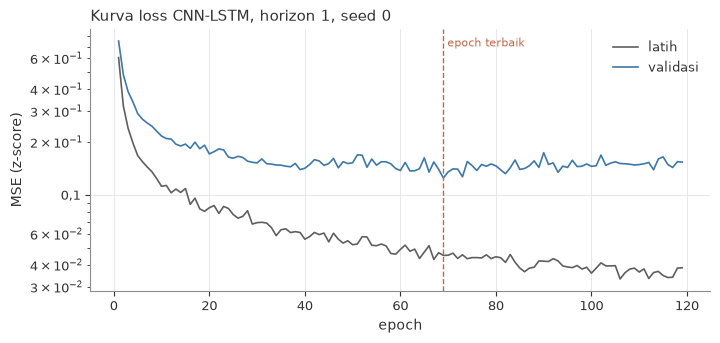

In [16]:
r0 = jalankan(NOTEBOOK, "baseline", "cnn_lstm", pm.TENGAH, DATA[1], 0)
WAKTU_SATU_RUN = float(r0["waktu_latih_s"])
print(f"satu run CNN-LSTM (h1, seed 0, pengaturan tengah): {WAKTU_SATU_RUN:.0f} detik, "
      f"{int(r0['n_epoch'])} epoch, epoch terbaik {int(r0['epoch_terbaik'])}, "
      f"{koma(WAKTU_SATU_RUN / int(r0['n_epoch']))} detik per epoch, NSE validasi {koma(float(r0['NSE']), d=3)}"
      f"{' (dari log)' if r0['dari_log'] else ''}")

fig, ax = plt.subplots(figsize=(8, 3.4))
ep = np.arange(1, len(r0["riwayat"]["loss"]) + 1)
ax.plot(ep, r0["riwayat"]["loss"], color=ABU_TUA, lw=1.2, label="latih")
ax.plot(ep, r0["riwayat"]["val_loss"], color=WARNA["utama"], lw=1.2, label="validasi")
ax.axvline(int(r0["epoch_terbaik"]), color=WARNA["aksen"], lw=1, ls="--")
ax.text(int(r0["epoch_terbaik"]), ax.get_ylim()[1], " epoch terbaik", va="top", fontsize=8, color=WARNA["aksen"])
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("MSE (z-score)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda y_, _: f"{y_:g}".replace(".", ",")))
ax.set_title("Kurva loss CNN-LSTM, horizon 1, seed 0", loc="left"); ax.legend()
simpan_gambar(fig, "kurva_loss_cnn_lstm_tengah_h1")

In [17]:
RUN["cnn_lstm"] = latih_semua("cnn_lstm")
ringkas_seed(RUN["cnn_lstm"])

  h1 seed 0: NSE 0,936, epoch terbaik 69/119, 76 s (dari log)
  h1 seed 1: NSE 0,934, epoch terbaik 70/120, 83 s (dari log)
  h1 seed 2: NSE 0,930, epoch terbaik 56/106, 69 s (dari log)
  h2 seed 0: NSE 0,644, epoch terbaik 17/67, 44 s (dari log)
  h2 seed 1: NSE 0,653, epoch terbaik 17/67, 45 s (dari log)
  h2 seed 2: NSE 0,648, epoch terbaik 21/71, 46 s (dari log)
  h3 seed 0: NSE 0,402, epoch terbaik 15/65, 43 s (dari log)
  h3 seed 1: NSE 0,408, epoch terbaik 15/65, 43 s (dari log)
  h3 seed 2: NSE 0,409, epoch terbaik 19/69, 46 s (dari log)


,NSE,KGE,RMSE,MAE,epoch_terbaik,waktu_latih_s
horizon,,,,,,
1,0.933 ± 0.003,0.949 ± 0.003,78.75 ± 1.747,33.008 ± 1.614,65.0 ± 7.81,76.027 ± 7.415
2,0.648 ± 0.004,0.686 ± 0.02,180.622 ± 1.127,69.151 ± 4.533,18.333 ± 2.309,44.947 ± 1.425
3,0.407 ± 0.004,0.422 ± 0.004,234.589 ± 0.743,100.501 ± 2.35,16.333 ± 2.309,44.123 ± 1.89


### Hasil

- Satu run CNN-LSTM (horizon 1, seed 0) berlangsung 76 detik: 119 epoch,
  epoch terbaik 69, sekitar 0,64 detik per epoch (CPU Apple M3 Pro).
- NSE CNN-LSTM 0,933 ± 0,003, 0,648 ± 0,004, dan 0,407 ± 0,004. Run horizon 2
  dan 3 berhenti lebih cepat (sekitar 67 epoch, epoch terbaik 16–18).

---
# Bagian IV — Ringkasan

## 11. Tabel baseline di bagian validasi

Dasar: deskriptif, tidak ada keputusan metodologis

Untuk jaringan saraf, angka di tabel adalah rata-rata ± simpangan baku atas 3
seed. Kolom `NSE_h1-3` adalah kriteria seleksi notebook 02. Tabel disimpan ke
`modeling/hasil/baseline_validasi.csv`.

In [18]:
baris = []
for (nama, h), m_ in HASIL_VAL.items():
    baris.append({"model": nama, "horizon": h, "seed": np.nan, **m_})
semua_run = pd.concat(RUN.values(), ignore_index=True)
baris += semua_run.drop(columns=["prediksi", "dari_log", "epoch_terbaik", "n_epoch", "waktu_latih_s"]).to_dict("records")
per_run = pd.DataFrame(baris)

URUTAN_MODEL = list(WARNA_MODEL)
rata = per_run.groupby(["model", "horizon"])[["NSE", "KGE", "RMSE", "MAE"]].mean()
sb = per_run.groupby(["model", "horizon"])[["NSE", "KGE", "RMSE", "MAE"]].std(ddof=1)
nse_seed = per_run.assign(seed=per_run["seed"].fillna(-1)).groupby(["model", "seed"])["NSE"].mean()
krit = nse_seed.groupby("model").agg(["mean", "std"])

tabel = pd.DataFrame(index=pd.Index(URUTAN_MODEL, name="model"))
for h in HORIZON:
    for k in ["NSE", "KGE"]:
        tabel[f"{k}_h{h}"] = [rata.loc[(m_, h), k] for m_ in URUTAN_MODEL]
tabel["RMSE_h1"] = [rata.loc[(m_, 1), "RMSE"] for m_ in URUTAN_MODEL]
tabel["MAE_h1"] = [rata.loc[(m_, 1), "MAE"] for m_ in URUTAN_MODEL]
tabel["NSE_h1-3"] = krit.loc[URUTAN_MODEL, "mean"].to_numpy()
tabel["sb_NSE_h1-3"] = krit.loc[URUTAN_MODEL, "std"].to_numpy()
tabel.round(4).to_csv(HASIL / "baseline_validasi.csv")
per_run.round(5).to_csv(HASIL / "baseline_validasi_per_run.csv", index=False)

tampil = tabel.copy()
for h in HORIZON:
    for k in ["NSE", "KGE"]:
        tampil[f"{k}_h{h}"] = [koma(rata.loc[(m_, h), k], d=3) + ("" if np.isnan(sb.loc[(m_, h), k]) else
                               " ± " + koma(sb.loc[(m_, h), k], d=3)) for m_ in URUTAN_MODEL]
tampil["RMSE_h1"] = [koma(v, d=1) for v in tabel["RMSE_h1"]]
tampil["MAE_h1"] = [koma(v, d=1) for v in tabel["MAE_h1"]]
tampil["NSE_h1-3"] = [koma(a, d=3) + ("" if np.isnan(s) else " ± " + koma(s, d=3))
                      for a, s in zip(tabel["NSE_h1-3"], tabel["sb_NSE_h1-3"])]
tampil.drop(columns="sb_NSE_h1-3")

,NSE_h1,KGE_h1,NSE_h2,KGE_h2,NSE_h3,KGE_h3,RMSE_h1,MAE_h1,NSE_h1-3
model,,,,,,,,,
klimatologi,"0,018","-0,046","0,018","-0,046","0,018","-0,046","301,8","166,8","0,018"
persistensi,"0,686","0,843","0,272","0,636","0,020","0,510","170,8","68,4","0,326"
ARIMA,"0,705","0,850","0,413","0,590","0,279","0,410","165,5","57,1","0,465"
regresi linear,"0,899","0,944","0,584","0,697","0,341","0,447","96,7","35,7","0,608"
LSTM target,"0,807 ± 0,002","0,849 ± 0,017","0,523 ± 0,012","0,575 ± 0,024","0,344 ± 0,007","0,364 ± 0,017","133,7","52,6","0,558 ± 0,006"
S_LSTM ala Le,"0,933 ± 0,003","0,938 ± 0,014","0,643 ± 0,004","0,671 ± 0,026","0,394 ± 0,015","0,408 ± 0,027","79,0","32,7","0,656 ± 0,005"
CNN-LSTM,"0,933 ± 0,003","0,949 ± 0,003","0,648 ± 0,004","0,686 ± 0,020","0,407 ± 0,004","0,422 ± 0,004","78,7","33,0","0,663 ± 0,002"


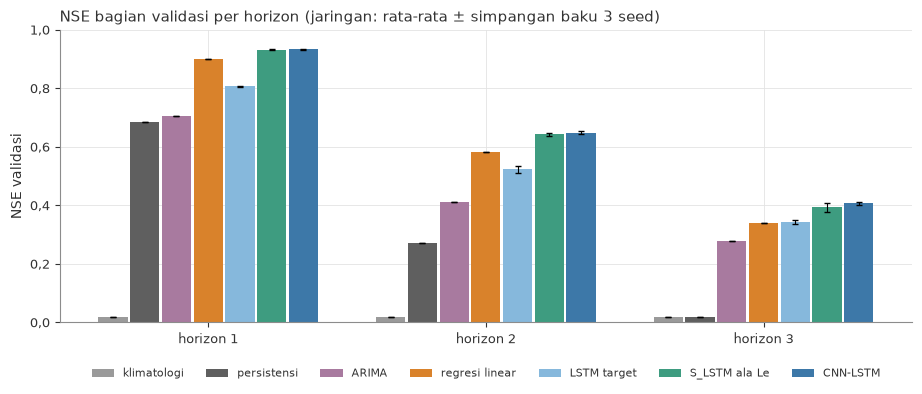

In [19]:
fig, ax = plt.subplots(figsize=(11, 3.8))
lebar = 0.8 / len(URUTAN_MODEL)
for j, m_ in enumerate(URUTAN_MODEL):
    x_ = np.arange(len(HORIZON)) + (j - (len(URUTAN_MODEL) - 1) / 2) * lebar
    y_ = [rata.loc[(m_, h), "NSE"] for h in HORIZON]
    e_ = [0 if np.isnan(sb.loc[(m_, h), "NSE"]) else sb.loc[(m_, h), "NSE"] for h in HORIZON]
    ax.bar(x_, y_, lebar * 0.92, yerr=e_, color=WARNA_MODEL[m_], label=m_, error_kw=dict(lw=0.8, capsize=2))
ax.set_xticks(range(len(HORIZON))); ax.set_xticklabels([f"horizon {h}" for h in HORIZON])
ax.set_ylim(max(0, per_run["NSE"].min() - 0.1), 1); sumbu_koma(ax, d=1)
ax.set_ylabel("NSE validasi")
ax.set_title("NSE bagian validasi per horizon (jaringan: rata-rata ± simpangan baku 3 seed)", loc="left")
ax.legend(ncol=7, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8)
simpan_gambar(fig, "baseline_nse_validasi")

Gambar berikut memperbesar kejadian debit tertinggi di bagian validasi. Prediksi
jaringan adalah rata-rata 3 seed.

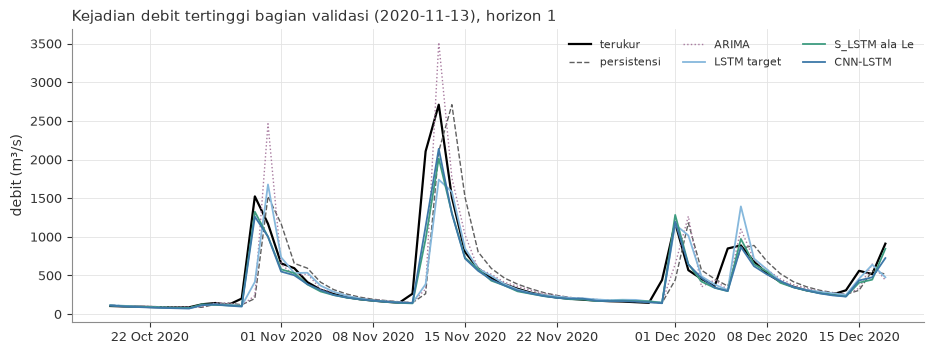

In [20]:
D1 = DATA[1]
obs = ke_m3s(D1["y_val"], D1)
i_puncak = int(np.argmax(obs))
jendela_plot = slice(max(0, i_puncak - 25), min(len(obs), i_puncak + 35))
t_ = D1["tanggal_val"][jendela_plot]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(t_, obs[jendela_plot], color="black", lw=1.6, label="terukur")
ax.plot(t_, ke_m3s(D1["X_val"][:, -1, D1["i_target"], 0], D1)[jendela_plot], color=WARNA_MODEL["persistensi"],
        lw=1, ls="--", label="persistensi")
ax.plot(t_, PRED_ARIMA[1][jendela_plot], color=WARNA_MODEL["ARIMA"], lw=1, ls=":", label="ARIMA")
for kode_m in ["lstm_target", "s_lstm", "cnn_lstm"]:
    tab = RUN[kode_m]
    p_ = np.mean(np.stack(tab[tab["horizon"] == 1]["prediksi"].to_list()), axis=0)
    ax.plot(t_, p_[jendela_plot], color=WARNA_MODEL[NAMA_MODEL[kode_m]], lw=1.3, label=NAMA_MODEL[kode_m])
ax.set_ylabel("debit (m³/s)"); sumbu_koma(ax, d=0)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Y"))
ax.set_title(f"Kejadian debit tertinggi bagian validasi ({D1['tanggal_val'][i_puncak].date()}), horizon 1", loc="left")
ax.legend(ncol=3, fontsize=8)
simpan_gambar(fig, "baseline_hidrograf_puncak_validasi")

### Hasil

- Urutan menurut rata-rata NSE horizon 1–3: CNN-LSTM 0,663 ± 0,002, S_LSTM
  0,656 ± 0,005, regresi linear 0,608, LSTM target 0,558, ARIMA 0,465,
  persistensi 0,326, klimatologi 0,018.
- Pada pengaturan tengah, CNN-LSTM dan S_LSTM praktis sama pada horizon 1
  (keduanya 0,933). Selisihnya baru terlihat pada horizon 2 dan 3 (0,005 dan
  0,013 NSE). Selisih rata-rata 0,007 hanya sekitar 1,5 kali simpangan baku
  antar-seed S_LSTM, dan kedua model belum dituning. Karena itu baseline ini
  belum menjadi bukti bahwa konvolusi sumbu pos lebih baik; perbandingan yang
  adil dikerjakan di notebook 02 dengan tuning yang sama untuk keduanya.
- Semua model turun tajam setelah horizon 1 (NSE terbaik 0,65 pada horizon 2
  dan 0,41 pada horizon 3). Lag perambatan antarpos paling lama 1 hari (tahap 23
  preprocessing), dan masukan tidak memuat hujan sesudah hari t, sehingga debit
  2–3 hari ke depan sebagian besar ditentukan oleh hujan yang belum terjadi.
- Pada kejadian 13 November 2020, ketiga jaringan meleset di bawah puncak
  (sekitar 1.740–2.140 m³/s terhadap 2.710 m³/s terukur), sedangkan ARIMA
  melampaui puncak sehari setelahnya.

## 12. Perkiraan waktu tahap A dan B

Dasar: deskriptif (aturan 0.6 brief pemodelan)

Waktu satu run = jumlah epoch × waktu per epoch. Keduanya diperkirakan terpisah:

- **Waktu per epoch** bergantung pada ukuran model dan tensor, bukan pada
  learning rate atau dropout. Waktu per epoch diukur untuk setiap kombinasi
  faktor yang memengaruhinya: CNN-LSTM 3 unit × 2 lapisan LSTM × 2 kernel ×
  2 lapisan konvolusi = 24 kombinasi; S_LSTM dan LSTM target 3 unit × 2 lapisan
  = 6 kombinasi; jendela 7–56 hari dan varian V18 dan V21 pada pengaturan
  tengah. Setiap kombinasi dilatih 4 epoch dan diambil median epoch 2–4 (epoch 1
  memuat waktu kompilasi). Tensor jendela 21, 28, dan 56 hari belum dibuat,
  jadi waktunya diukur dengan tensor acak berbentuk sama; isinya tidak
  memengaruhi waktu.
- **Jumlah epoch** diambil dari run baseline di tahap 8–10, per jenis model.
  Batas atasnya 300 epoch.

Jumlah run: tahap A memakai CNN-LSTM, 3 seed × 3 horizon per pilihan, dan run
pilihan dasar (jendela 14, Daymet, log1p, V17) diambil dari tahap 10. Tahap B
dijalankan untuk ketiga jaringan: 24 titik Latin hypercube × 3 seed × 3
horizon, lalu 3 finalis × 5 seed tambahan × 3 horizon, ditambah MC Dropout 1.000
lintasan pada validasi untuk 3 finalis × 8 seed × 3 horizon.

Tampilkan dulu: waktu per epoch.

In [21]:
import itertools

class JamEpoch(keras.callbacks.Callback):
    def on_epoch_begin(self, epoch, logs=None):
        self.t = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        self.w.append(time.perf_counter() - self.t)

def detik_per_epoch(kode_m, cfg, D, jendela=14, n_epoch=4):
    Xl, Xv, yl = D["X_latih"], D["X_val"], D["y_latih"]
    if jendela < Xl.shape[1]:
        Xl, Xv = Xl[:, -jendela:], Xv[:, -jendela:]
    elif jendela > Xl.shape[1]:                  # tensor acak berbentuk sama, hanya untuk mengukur waktu
        rng = np.random.default_rng(0)
        n_l = len(Xl) - (jendela - Xl.shape[1])
        Xl = rng.standard_normal((n_l, jendela) + Xl.shape[2:]).astype(np.float32)
        Xv = rng.standard_normal((len(Xv), jendela) + Xv.shape[2:]).astype(np.float32)
        yl = yl[:n_l]
    keras.backend.clear_session(); keras.utils.set_random_seed(0)
    Xl, Xv = pm.bentuk_masukan(Xl, kode_m, D["i_target"]), pm.bentuk_masukan(Xv, kode_m, D["i_target"])
    m_ = pm.bangun_model(kode_m, cfg, Xl.shape[1:])
    jam = JamEpoch(); jam.w = []
    m_.fit(Xl, yl, validation_data=(Xv, D["y_val"]), epochs=n_epoch, batch_size=pm.TETAP["batch"],
           verbose=0, callbacks=[jam])
    return float(np.median(jam.w[1:]))

t0 = time.perf_counter()
UKUR = []
for u, l, k, c in itertools.product([32, 64, 128], [1, 2], [2, 3], [1, 2]):
    cfg = {**pm.TENGAH, "unit": u, "lapisan_lstm": l, "kernel": k, "lapisan_konv": c}
    UKUR.append({"model": "cnn_lstm", "unit": u, "lapisan_lstm": l, "kernel": k, "lapisan_konv": c,
                 "jendela": 14, "varian": "V17", "detik_per_epoch": detik_per_epoch("cnn_lstm", cfg, DATA[1])})
for kode_m in ["s_lstm", "lstm_target"]:
    for u, l in itertools.product([32, 64, 128], [1, 2]):
        cfg = {**pm.TENGAH, "unit": u, "lapisan_lstm": l}
        UKUR.append({"model": kode_m, "unit": u, "lapisan_lstm": l, "jendela": 14, "varian": "V17",
                     "detik_per_epoch": detik_per_epoch(kode_m, cfg, DATA[1])})
for w in [7, 8, 14, 21, 28, 56]:
    UKUR.append({"model": "cnn_lstm", **pm.TENGAH, "jendela": w, "varian": "V17", "langkah": "A1",
                 "detik_per_epoch": detik_per_epoch("cnn_lstm", pm.TENGAH, DATA[1], jendela=w)})
for v in ["V18", "V21"]:
    UKUR.append({"model": "cnn_lstm", **pm.TENGAH, "jendela": 14, "varian": v, "langkah": "A4",
                 "detik_per_epoch": detik_per_epoch("cnn_lstm", pm.TENGAH, muat_latih_val(1, v))})
UKUR = pd.DataFrame(UKUR)
UKUR.to_csv(HASIL / "waktu_per_epoch.csv", index=False)
print(f"pengukuran selesai dalam {time.perf_counter() - t0:.0f} detik\n")

cnn = UKUR[(UKUR["model"] == "cnn_lstm") & UKUR["langkah"].isna()]
print("CNN-LSTM, detik per epoch (baris: unit, lapisan LSTM; kolom: kernel, lapisan konvolusi)")
print(cnn.pivot_table(index=["unit", "lapisan_lstm"], columns=["kernel", "lapisan_konv"],
                      values="detik_per_epoch").round(2).to_string())
for kode_m in ["s_lstm", "lstm_target"]:
    print(f"\n{NAMA_MODEL[kode_m]}, detik per epoch (baris: unit; kolom: lapisan LSTM)")
    print(UKUR[(UKUR["model"] == kode_m)].pivot_table(index="unit", columns="lapisan_lstm",
                                                      values="detik_per_epoch").round(2).to_string())
print("\nCNN-LSTM pengaturan tengah per jendela dan varian:")
print(UKUR[UKUR["langkah"].notna()][["langkah", "jendela", "varian", "detik_per_epoch"]].round(2).to_string(index=False))

pengukuran selesai dalam 191 detik

CNN-LSTM, detik per epoch (baris: unit, lapisan LSTM; kolom: kernel, lapisan konvolusi)
kernel              2.0         3.0      
lapisan_konv        1.0   2.0   1.0   2.0
unit lapisan_lstm                        
32   1             0.22  0.26  0.21  0.26
     2             0.28  0.32  0.28  0.33
64   1             0.47  0.60  0.46  0.61
     2             0.61  0.74  0.60  0.76
128  1             1.32  1.92  1.29  1.95
     2             2.08  2.34  1.58  2.23

S_LSTM ala Le, detik per epoch (baris: unit; kolom: lapisan LSTM)
lapisan_lstm     1     2
unit                    
32            0.10  0.17
64            0.17  0.31
128           0.30  0.58

LSTM target, detik per epoch (baris: unit; kolom: lapisan LSTM)
lapisan_lstm     1     2
unit                    
32            0.08  0.15
64            0.14  0.27
128           0.24  0.54

CNN-LSTM pengaturan tengah per jendela dan varian:
langkah  jendela varian  detik_per_epoch
     A1        7    V17

In [22]:
# MC Dropout: waktu 100 lintasan pada seluruh sampel validasi, diekstrapolasi ke 1.000
def detik_mc(kode_m, D, lintasan=100):
    keras.backend.clear_session(); keras.utils.set_random_seed(0)
    Xv = pm.bentuk_masukan(D["X_val"], kode_m, D["i_target"])
    m_ = pm.bangun_model(kode_m, pm.TENGAH, Xv.shape[1:])
    f_ = tf.function(lambda x: m_(x, training=True))
    xv = tf.constant(Xv); f_(xv)
    t0 = time.perf_counter()
    for _ in range(lintasan):
        f_(xv)
    return (time.perf_counter() - t0) * 1000 / lintasan
MC_1000 = {kode_m: detik_mc(kode_m, DATA[1]) for kode_m in NAMA_MODEL}
for kode_m, s in MC_1000.items():
    print(f"MC Dropout 1.000 lintasan x {ribu(len(DATA[1]['y_val']))} sampel validasi, {NAMA_MODEL[kode_m]}: {s:.0f} detik")

MC Dropout 1.000 lintasan x 1.370 sampel validasi, LSTM target: 13 detik
MC Dropout 1.000 lintasan x 1.370 sampel validasi, S_LSTM ala Le: 16 detik
MC Dropout 1.000 lintasan x 1.370 sampel validasi, CNN-LSTM: 43 detik


In [23]:
# jumlah epoch per run dari baseline; faktor overhead = waktu run tercatat / (epoch x detik per epoch terukur)
dpe_tengah = {m_: float(UKUR[(UKUR["model"] == m_) & (UKUR["unit"] == 64) & (UKUR["lapisan_lstm"] == 2)
                             & UKUR["langkah"].isna() & ((UKUR["kernel"].isna()) | ((UKUR["kernel"] == 2)
                             & (UKUR["lapisan_konv"] == 1)))]["detik_per_epoch"].iloc[0]) for m_ in NAMA_MODEL}
EPOCH, OVERHEAD = {}, {}
for m_, tab in RUN.items():
    EPOCH[m_] = (tab["n_epoch"].mean(), tab["n_epoch"].min(), tab["n_epoch"].max())
    OVERHEAD[m_] = float((tab["waktu_latih_s"] / (tab["n_epoch"] * dpe_tengah[m_])).median())
    print(f"{NAMA_MODEL[m_]:14}: epoch per run rata-rata {EPOCH[m_][0]:.0f} (rentang {EPOCH[m_][1]}–{EPOCH[m_][2]}), "
          f"waktu per run rata-rata {tab['waktu_latih_s'].mean():.0f} detik, faktor overhead {OVERHEAD[m_]:.2f}")

def jam(n_run, dpe, m_, epoch=None):
    e = EPOCH[m_][0] if epoch is None else epoch
    return n_run * e * dpe * OVERHEAD[m_] / 3600

dpe_rata = {m_: float(UKUR[(UKUR["model"] == m_) & UKUR["langkah"].isna()]["detik_per_epoch"].mean())
            for m_ in NAMA_MODEL}
dpe_w = UKUR[UKUR["langkah"] == "A1"].set_index("jendela")["detik_per_epoch"]
dpe_v = UKUR[UKUR["langkah"] == "A4"].set_index("varian")["detik_per_epoch"]
N_SH = 3 * len(HORIZON)                  # 3 seed x 3 horizon per pilihan

rinci = []
def tambah(tahap, langkah, isi, n_run, dpe, m_, mc=0.0):
    rinci.append({"tahap": tahap, "langkah": langkah, "isi": isi, "run_baru": n_run,
                  "jam": jam(n_run, dpe, m_) + mc / 3600,
                  "jam_bila_300_epoch": jam(n_run, dpe, m_, epoch=300) + mc / 3600})

for w in [7, 8, 21, 28, 56]:
    tambah("A", "A1", f"jendela {w} hari", N_SH, dpe_w[w], "cnn_lstm")
tambah("A", "A2", "hujan GHCN (jendela 14)", N_SH, dpe_w[14], "cnn_lstm")
tambah("A", "A3", "log10(√x + 0,1) (jendela 14)", N_SH, dpe_w[14], "cnn_lstm")
for v in ["V18", "V21"]:
    tambah("A", "A4", f"{v} (jendela 14)", N_SH, dpe_v[v], "cnn_lstm")
for m_ in NAMA_MODEL:
    tambah("B", NAMA_MODEL[m_], "24 titik x 3 seed x 3 horizon", 24 * N_SH, dpe_rata[m_], m_)
    tambah("B", NAMA_MODEL[m_], "3 finalis x 5 seed tambahan x 3 horizon", 3 * 5 * len(HORIZON), dpe_rata[m_], m_)
    tambah("B", NAMA_MODEL[m_], "MC Dropout 1.000 lintasan, 3 finalis x 8 seed x 3 horizon", 0, 0, m_,
           mc=3 * 8 * len(HORIZON) * MC_1000[m_])
PERKIRAAN = pd.DataFrame(rinci)
PERKIRAAN.round(3).to_csv(HASIL / "perkiraan_waktu.csv", index=False)

tampil = PERKIRAAN.copy()
tampil["jam"] = tampil["jam"].map(lambda x: koma(x, d=2))
tampil["jam_bila_300_epoch"] = tampil["jam_bila_300_epoch"].map(lambda x: koma(x, d=2))
print(tampil.to_string(index=False))
tot = PERKIRAAN.groupby("tahap")[["run_baru", "jam", "jam_bila_300_epoch"]].sum()
print("\ntotal per tahap (berurutan, satu proses):")
print(tot.round(1).to_string())
print(f"\ntotal A + B: {koma(tot['jam'].sum(), d=1)} jam (batas atas bila semua run mencapai 300 epoch: "
      f"{koma(tot['jam_bila_300_epoch'].sum(), d=1)} jam)")

# bila A1 memilih jendela 56, langkah A2-A4 ikut memakai jendela 56
skala56 = dpe_w[56] / dpe_w[14]
a234 = PERKIRAAN[PERKIRAAN["langkah"].isin(["A2", "A3", "A4"])]["jam"].sum()
print(f"bila A1 memilih jendela 56 hari: tahap A menjadi sekitar {koma(tot.loc['A', 'jam'] + a234 * (skala56 - 1), d=1)} jam")

LSTM target   : epoch per run rata-rata 69 (rentang 57–86), waktu per run rata-rata 21 detik, faktor overhead 1.12
S_LSTM ala Le : epoch per run rata-rata 87 (rentang 59–150), waktu per run rata-rata 29 detik, faktor overhead 1.07
CNN-LSTM      : epoch per run rata-rata 83 (rentang 65–120), waktu per run rata-rata 55 detik, faktor overhead 1.08
tahap       langkah                                                       isi  run_baru  jam jam_bila_300_epoch
    A            A1                                            jendela 7 hari         9 0,08               0,27
    A            A1                                            jendela 8 hari         9 0,09               0,31
    A            A1                                           jendela 21 hari         9 0,21               0,76
    A            A1                                           jendela 28 hari         9 0,26               0,95
    A            A1                                           jendela 56 hari         9 0,52 

### Hasil

| Tahap | Run baru | Perkiraan (jam) | Batas atas, semua run 300 epoch (jam) |
|---|---|---|---|
| A (CNN-LSTM, 9 pilihan baru × 3 seed × 3 horizon) | 81 | 1,8 | 6,5 |
| B (3 jaringan × 261 run, ditambah MC Dropout finalis) | 783 | 10,5 | 34,7 |
| **Total A + B** | **864** | **12,3** | **41,2** |

- Perkiraan ini untuk satu proses yang berjalan berurutan. Sebagian besar waktu
  tahap B dipakai CNN-LSTM (6,7 dari 10,5 jam), karena konfigurasi 128 unit
  dengan 2 lapisan konvolusi memerlukan sekitar 2,2 detik per epoch, delapan
  kali konfigurasi 32 unit.
- Bila A1 memilih jendela 56 hari, langkah A2–A4 ikut memakai jendela 56 dan
  tahap A menjadi sekitar 3,2 jam.
- Jumlah epoch diambil dari pengaturan tengah (rata-rata 69–87 per run). Titik
  dengan learning rate 0,0005 kemungkinan memerlukan lebih banyak epoch, jadi
  angka 12,3 jam lebih mungkin terlampaui daripada kurang. Batas atasnya 41,2 jam.
- Waktu per epoch berubah sekitar 5–15 persen antar-pengukuran, tergantung
  beban komputer.

Waktu jalan notebook:

In [24]:
print(f"waktu jalan notebook: {(time.time() - MULAI_JALAN) / 60:.1f} menit")
print(f"run di log: {len(baca_log())}")

waktu jalan notebook: 3.8 menit
run di log: 27
